# 01 · Exploratory Data Analysis: M5 Forecasting Accuracy

**PRISM:** Probabilistic Retail Inventory forecasting with State-space & Machine learning

This notebook covers the data-quality checks and EDA that shape every modelling decision later on:

1. Data structure and integrity checks
2. Aggregate behaviour: trend, weekly / yearly seasonality, store closures
3. Intermittency: why the Syntetos–Boylan demand classes matter
4. The experiment sample (1,500 series) and how it was stratified
5. Prices, SNAP and calendar events: the exogenous signals
6. Launch dates and why cold start is a real problem

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from prism.config import load_config, resolve
from prism.data import load_raw, load_panel, first_sale
from prism.sampling import DEMAND_CLASSES
from prism import plots
plots.apply_style()
FIG = resolve("report/figures")
cfg = load_config()
meta_all, Y_all, calendar, prices = load_raw(resolve(cfg["data"]["raw_dir"]))
print(f"series: {Y_all.shape[0]:,}   days: {Y_all.shape[1]:,}   calendar days: {len(calendar):,}   price rows: {len(prices):,}")

series: 30,490   days: 1,941   calendar days: 1,969   price rows: 6,841,121


## 1. Structure and integrity checks
M5 covers 3,049 products × 10 stores in 3 US states (CA, TX, WI), with daily unit sales from 2011-01-29 to 2016-05-22 (d_1 … d_1941). The hierarchy runs state → store → category → department → item.

In [2]:
print(meta_all.nunique().to_frame("unique values").T.to_string())
checks = {
    "negative sales values": int((Y_all < 0).sum()),
    "missing sales values": int(np.isnan(Y_all).sum()),
    "duplicate series ids": int(meta_all["id"].duplicated().sum()),
    "calendar dates contiguous": bool((calendar["date"].diff().dropna() == pd.Timedelta("1D")).all()),
    "duplicate (store, item, week) prices": int(prices.duplicated(["store_id", "item_id", "wm_yr_wk"]).sum()),
    "non-positive prices": int((prices["sell_price"] <= 0).sum()),
}
pd.Series(checks, name="result").to_frame()

                  id  item_id  dept_id  cat_id  store_id  state_id
unique values  30490     3049        7       3        10         3


,result
negative sales values,0
missing sales values,0
duplicate series ids,0
calendar dates contiguous,True
"duplicate (store, item, week) prices",0
non-positive prices,0


The data is clean (no negative or missing sales, no duplicates, a contiguous calendar). Its real problems are about *meaning* rather than formatting:
* a **zero** can mean "no demand", "not yet launched" or "out of stock". The raw data does not say which.
* prices exist only for weeks when an item is on the shelf, so a missing price is information (not launched yet).

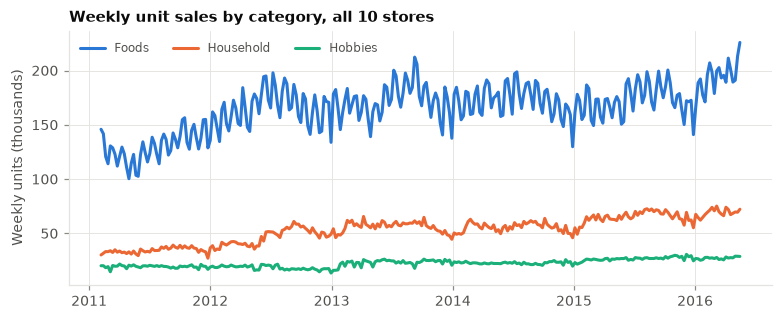

In [3]:
cat_totals = pd.DataFrame(Y_all.T, index=calendar["date"].iloc[:Y_all.shape[1]]).T.groupby(meta_all["cat_id"].values).sum().T
weekly = cat_totals.resample("W").sum().iloc[1:-1]
fig, ax = plt.subplots(figsize=(7, 2.8))
cat_colors = {"FOODS": "#2a78d6", "HOUSEHOLD": "#eb6834", "HOBBIES": "#1baf7a"}
for c in ["FOODS", "HOUSEHOLD", "HOBBIES"]:
    ax.plot(weekly.index, weekly[c] / 1e3, color=cat_colors[c], label=c.title())
ax.set_ylabel("Weekly units (thousands)"); ax.set_title("Weekly unit sales by category, all 10 stores")
ax.legend(loc="upper left", ncols=3)
plots.save(fig, FIG / "eda_category_trend.pdf")

## 2. Seasonality and closures
Day-of-week effects are strong and stable, so a weekly seasonal component is the first thing any model must capture. That motivates the seasonal naive baseline and the 7-state seasonal block in the Kalman filter.

days with (near-)zero total sales, i.e. store closures: ['2011-12-25', '2012-12-25', '2013-12-25', '2014-12-25', '2015-12-25']


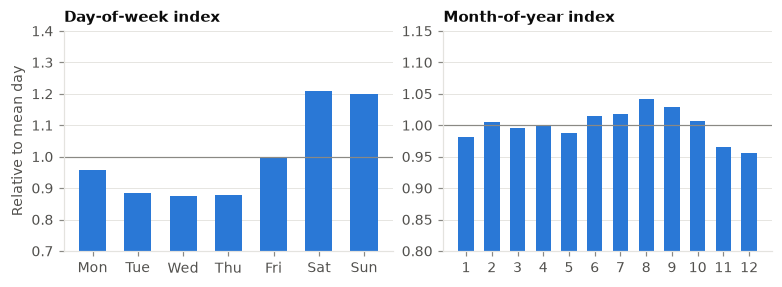

In [4]:
daily_total = pd.Series(Y_all.sum(0), index=calendar["date"].iloc[:Y_all.shape[1]])
dow = daily_total.groupby(daily_total.index.dayofweek).mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
month = daily_total.groupby(daily_total.index.month).mean()
fig, axes = plt.subplots(1, 2, figsize=(7, 2.5))
axes[0].bar(dow.index, dow / dow.mean(), color="#2a78d6", width=0.6); axes[0].axhline(1, color=plots.INK_3, lw=0.8)
axes[0].set_title("Day-of-week index"); axes[0].set_ylabel("Relative to mean day"); axes[0].grid(axis="x", visible=False)
axes[1].bar(month.index, month / month.mean(), color="#2a78d6", width=0.6); axes[1].axhline(1, color=plots.INK_3, lw=0.8)
axes[1].set_title("Month-of-year index"); axes[1].set_xticks(range(1, 13)); axes[1].grid(axis="x", visible=False)
axes[1].set_ylim(0.8, 1.15); axes[0].set_ylim(0.7, 1.4)
plots.save(fig, FIG / "eda_seasonality.pdf")
closed = daily_total[daily_total < 0.1 * daily_total.median()]
print("days with (near-)zero total sales, i.e. store closures:", list(closed.index.strftime("%Y-%m-%d")))

Saturdays and Sundays sell about 25 % above the average day, roughly 45 % above mid-week. All stores close on **Christmas Day**, so total sales drop to roughly zero. Those zeros are not demand, and the stockout marker (notebook 02) flags them on busy series, so they never teach a model that Christmas demand is zero.

## 3. Intermittency
Most item-store series are **intermittent**: many days have zero sales. Following Syntetos & Boylan (2005), each series is classified by
* **ADI**, the average inter-demand interval (timing irregularity), and
* **CV²**, the squared coefficient of variation of the non-zero demand sizes (size irregularity),

with the cut-offs ADI = 1.32 and CV² = 0.49.

median zero share: 0.63;  series with >50% zero days: 67%


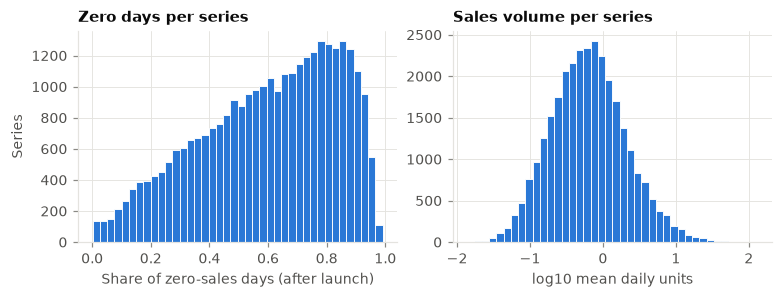

In [5]:
launch_all = first_sale(Y_all)
active = np.arange(Y_all.shape[1])[None, :] >= launch_all[:, None]
zero_share = ((Y_all == 0) & active).sum(1) / active.sum(1).clip(1)
mean_sales = (Y_all * active).sum(1) / active.sum(1).clip(1)
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6))
axes[0].hist(zero_share, bins=40, color="#2a78d6", edgecolor="white", linewidth=0.6)
axes[0].set_xlabel("Share of zero-sales days (after launch)"); axes[0].set_ylabel("Series"); axes[0].set_title("Zero days per series")
axes[1].hist(np.log10(mean_sales + 1e-3), bins=40, color="#2a78d6", edgecolor="white", linewidth=0.6)
axes[1].set_xlabel("log10 mean daily units"); axes[1].set_title("Sales volume per series")
plots.save(fig, FIG / "eda_intermittency.pdf")
print(f"median zero share: {np.median(zero_share):.2f};  series with >50% zero days: {(zero_share > 0.5).mean():.0%}")

## 4. The experiment sample
Phase 1 uses **one store per state** (CA_1, TX_1, WI_1) and **500 series per store**. The series are sampled *balanced* over category × demand class, so rare but important regimes (smooth HOBBIES items, lumpy FOODS items) are still represented. A purely random sample would be ~70 % intermittent/lumpy. Demand classes are computed **only from history before the first forecast origin**, so the sample design uses no test data.

demand_class,erratic,intermittent,lumpy,new,smooth,All
cat_id,,,,,,
FOODS,156,161,159,2,159,637
HOBBIES,22,160,159,0,13,354
HOUSEHOLD,43,161,151,1,153,509
All,221,482,469,3,325,1500


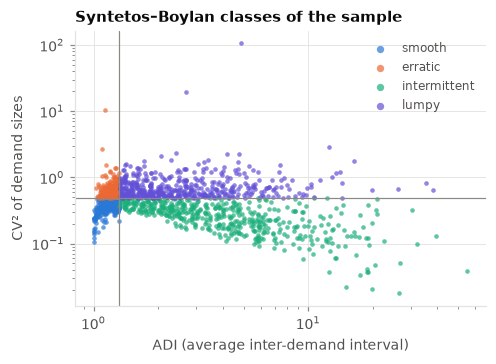

In [6]:
panel = load_panel(cfg)
m = panel.meta
display(pd.crosstab(m["cat_id"], m["demand_class"], margins=True))
fig, ax = plt.subplots(figsize=(4.4, 3.2))
klass_colors = {"smooth": "#2a78d6", "erratic": "#eb6834", "intermittent": "#1baf7a", "lumpy": "#6250d6"}
for k in DEMAND_CLASSES:
    d = m[m["demand_class"] == k]
    ax.scatter(d["adi"], d["cv2"], s=9, color=klass_colors[k], label=k, alpha=0.7, linewidths=0)
ax.axvline(1.32, color=plots.INK_3, lw=0.8); ax.axhline(0.49, color=plots.INK_3, lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("ADI (average inter-demand interval)"); ax.set_ylabel("CV² of demand sizes")
ax.set_title("Syntetos–Boylan classes of the sample"); ax.legend(loc="upper right", markerscale=1.6)
plots.save(fig, FIG / "eda_demand_classes.pdf")

## 5. Exogenous signals: prices, SNAP, events
These are known **in advance** (the retailer sets prices and knows the calendar), so the global model may use their values on the target day without leaking anything.

share of item-weeks with a price change: 1.1%


,state,uplift on SNAP days
0,CA,0.103
1,TX,0.160
2,WI,0.064


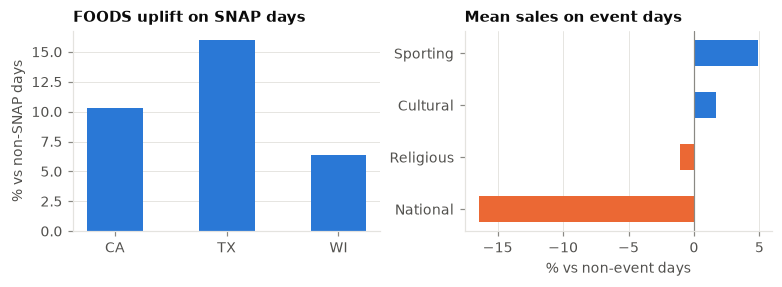

In [7]:
obs = ~np.isnan(panel.y)
weekly_price = panel.price[:, :panel.n_days:7]                 # one value per Walmart week
d = np.diff(weekly_price, axis=1)
valid = ~np.isnan(d)
print(f"share of item-weeks with a price change: {(np.abs(d[valid]) > 1e-6).mean():.1%}")
# SNAP effect on FOODS, per state: mean units on SNAP vs non-SNAP days
rows = []
for st in ["CA", "TX", "WI"]:
    sel = (m["state_id"] == st) & (m["cat_id"] == "FOODS")
    snap = calendar[f"snap_{st}"].to_numpy()[:panel.n_days].astype(bool)
    y = panel.y[sel.to_numpy()]
    rows.append({"state": st, "uplift on SNAP days": np.nanmean(y[:, snap]) / np.nanmean(y[:, ~snap]) - 1})
snap_df = pd.DataFrame(rows)
ev = calendar["event_type_1"].iloc[:panel.n_days]
ev_uplift = pd.Series({t: np.nanmean(panel.y[:, (ev == t).to_numpy()]) / np.nanmean(panel.y[:, ev.isna().to_numpy()]) - 1
                       for t in ev.dropna().unique()})
fig, axes = plt.subplots(1, 2, figsize=(7, 2.5))
axes[0].bar(snap_df["state"], snap_df["uplift on SNAP days"] * 100, color="#2a78d6", width=0.5)
axes[0].set_title("FOODS uplift on SNAP days"); axes[0].set_ylabel("% vs non-SNAP days"); axes[0].grid(axis="x", visible=False)
ev_uplift = ev_uplift.sort_values()
axes[1].barh(ev_uplift.index, ev_uplift * 100, color=["#eb6834" if v < 0 else "#2a78d6" for v in ev_uplift], height=0.5)
axes[1].axvline(0, color=plots.INK_3, lw=0.8)
axes[1].set_title("Mean sales on event days"); axes[1].set_xlabel("% vs non-event days"); axes[1].grid(axis="y", visible=False)
plots.save(fig, FIG / "eda_snap_events.pdf")
snap_df.round(3)

SNAP days (food-stamp disbursement days, which differ by state) lift FOODS sales noticeably, so the state-specific SNAP flag is a feature. Event types move sales in both directions: national holidays *reduce* sales by about 16 %, while sporting events lift them slightly. Prices change rarely (about 1 % of item-weeks), so the price features carry signal mainly at promotions.

## 6. Launch dates and cold start

series launched after day 1: 77%;  after day 1000: 4,941
cold-start series in the sample: 150 simulated + 3 naturally new


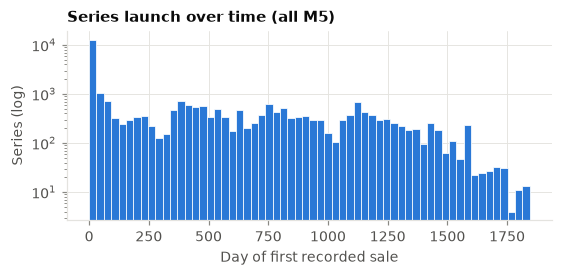

In [8]:
fig, ax = plt.subplots(figsize=(5, 2.4))
ax.hist(launch_all[launch_all < Y_all.shape[1]], bins=60, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.set_yscale("log"); ax.set_xlabel("Day of first recorded sale"); ax.set_ylabel("Series (log)")
ax.set_title("Series launch over time (all M5)")
plots.save(fig, FIG / "eda_launch.pdf")
print(f"series launched after day 1: {(launch_all > 0).mean():.0%};  after day 1000: {(launch_all > 1000).sum():,}")
print("cold-start series in the sample:", int(m["sim_cold_start"].sum()), "simulated +",
      int((m["demand_class"] == "new").sum()), "naturally new")

Real launches after the first forecast origin are rare in M5 (only a handful in our stores). To *measure* cold-start behaviour we therefore **simulate** it (notebook 02): 10 % of established series have their history hidden so they "launch" 7–56 days before the first origin. Their true history is never used, not even through cross-store aggregates, because each series' own sales are subtracted from those aggregates.

### Takeaways for modelling
| Observation | Consequence |
|---|---|
| Strong, stable weekly pattern | seasonal naive baseline; 7-state seasonal block in the Kalman filter; day-of-week features |
| ~2/3 of series intermittent or lumpy | log1p scale for the filter; Tweedie loss for LightGBM; TSB as an intermittent-demand reference |
| Zeros that are not demand (closures, stockouts) | *mark* likely stockouts, then mask them in training and in the Kalman update |
| Prices, SNAP and events matter | known-ahead exogenous features for the global model |
| New items have little or no history | cold-start segment; cross-store features that let a global model borrow strength |